In [1]:
import numpy as np
import os
from scipy.misc import imread, imresize
import datetime
import os
import warnings
warnings.filterwarnings("ignore")
import cv2

In [2]:
# We set the random seed so that the results don't vary drastically.

In [3]:
np.random.seed(30)
import random as rn
rn.seed(30)
from keras import backend as K
import tensorflow as tf
tf.set_random_seed(30)
#tf.random.set_seed(30)

Using TensorFlow backend.


In [4]:
import cv2
import matplotlib.pyplot as plt
%matplotlib inline

In [5]:
from keras.models import Sequential, Model
from keras.layers import Dense, GRU, Flatten, TimeDistributed, Flatten, BatchNormalization, Activation, Dropout
from keras.layers.convolutional import Conv3D, MaxPooling3D
from keras.callbacks import ModelCheckpoint, ReduceLROnPlateau
from keras import optimizers
from keras.optimizers import Adam

In [6]:
def plot(history):
    fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(15,4))
    axes[0].plot(history.history['loss'])   
    axes[0].plot(history.history['val_loss'])
    axes[0].legend(['loss','val_loss'])

    axes[1].plot(history.history['categorical_accuracy'])   
    axes[1].plot(history.history['val_categorical_accuracy'])
    axes[1].legend(['categorical_accuracy','val_categorical_accuracy'])



# Model with No Data Augmentation

In [66]:
# In this block, you read the folder names for training and validation. You also set the batch_size here. Note that you set the batch size in such a way that you are able to use the GPU in full capacity. You keep increasing the batch size until the machine throws an error.

In [85]:
train_doc = np.random.permutation(open('train.csv').readlines())
val_doc = np.random.permutation(open('val.csv').readlines())

In [86]:
batch_size = 40

In [87]:
# Generator
# This is one of the most important part of the code. The overall structure of the generator has been given. In the generator, you are going to preprocess the images as you have images of 2 different dimensions as well as create a batch of video frames. You have to experiment with img_idx, y,z and normalization such that you get high accuracy.

In [89]:
def generator(source_path, folder_list, batch_size, augment=False):
    print( 'Source path = ', source_path, '; batch size =', batch_size)
    img_idx = [0,1,2,4,6,8,10,12,14,16,18,20,22,24,26,27,28,29]
    while True:
        t = np.random.permutation(folder_list)
        num_batches = int(len(t)/batch_size)
        for batch in range(num_batches):
            batch_data = np.zeros((batch_size,18,160,160,3))
            batch_labels = np.zeros((batch_size,5))
            for folder in range(batch_size):
                imgs = os.listdir(source_path+'/'+ t[folder + (batch*batch_size)].split(';')[0])
                for idx,item in enumerate(img_idx):
                    image = imread(source_path+'/'+ t[folder + (batch*batch_size)].strip().split(';')[0]+'/'+imgs[item]).astype(np.float32)
                    if image.shape[1] == 160:
                        image = imresize(image[:,20:140,:],(160,160)).astype(np.float32)
                    else:
                        image = imresize(image,(160,160)).astype(np.float32)
                    
                    batch_data[folder,idx,:,:,0] = image[:,:,0] - 104
                    batch_data[folder,idx,:,:,1] = image[:,:,1] - 117
                    batch_data[folder,idx,:,:,2] = image[:,:,2] - 123
                    
                batch_labels[folder, int(t[folder + (batch*batch_size)].strip().split(';')[2])] = 1
            yield batch_data, batch_labels

        if (len(t)%batch_size) != 0:
            batch_data = np.zeros((len(t)%batch_size,18,160,160,3))
            batch_labels = np.zeros((len(t)%batch_size,5))
            for folder in range(len(t)%batch_size):
                imgs = os.listdir(source_path+'/'+ t[folder + (num_batches*batch_size)].split(';')[0])
                for idx,item in enumerate(img_idx):
                    image = imread(source_path+'/'+ t[folder + (num_batches*batch_size)].strip().split(';')[0]+'/'+imgs[item]).astype(np.float32)
                    if image.shape[1] == 160:
                        image = imresize(image[:,20:140,:],(160,160)).astype(np.float32)
                    else:
                        image = imresize(image,(160,160)).astype(np.float32)

                    batch_data[folder,idx,:,:,0] = image[:,:,0] - 104
                    batch_data[folder,idx,:,:,1] = image[:,:,1] - 117
                    batch_data[folder,idx,:,:,2] = image[:,:,2] - 123

                batch_labels[folder, int(t[folder + (num_batches*batch_size)].strip().split(';')[2])] = 1

            yield batch_data, batch_labels

In [90]:
# Note here that a video is represented above in the generator as (number of images, height, width, number of channels). Take this into consideration while creating the model architecture.

In [91]:
curr_dt_time = datetime.datetime.now()
train_path = 'train'
val_path = 'val'
num_train_sequences = len(train_doc)
print('# training sequences =', num_train_sequences)
num_val_sequences = len(val_doc)
print('# validation sequences =', num_val_sequences)
num_epochs = 15 # choose the number of epochs
print ('# epochs =', num_epochs)

# training sequences = 663
# validation sequences = 100
# epochs = 15


In [92]:
# Model
# Here you make the model using different functionalities that Keras provides. Remember to use Conv3D and MaxPooling3D and not Conv2D and Maxpooling2D for a 3D convolution model. You would want to use TimeDistributed while building a Conv2D + RNN model. Also remember that the last layer is the softmax. Design the network in such a way that the model is able to give good accuracy on the least number of parameters so that it can fit in the memory of the webcam.

In [103]:
#write your model here
input_shape = (18, 160, 160, 3)
model = Sequential([
    Conv3D(16, (3,3,3), padding='same', activation='relu', input_shape=input_shape),
    BatchNormalization(),
    MaxPooling3D(pool_size=(2,2,2)),
    
    Conv3D(32, (2,2,2), padding='same', activation='relu'),
    BatchNormalization(),
    MaxPooling3D(pool_size=(2,2,2)),    
    
    Conv3D(64, (2,2,2), padding='same', activation='relu'),
    BatchNormalization(),
    MaxPooling3D(pool_size=(2,2,2)),
    
    Conv3D(128, (2,2,2), padding='same', activation='relu'),
    BatchNormalization(),
    MaxPooling3D(pool_size=(2,2,2)),
    
       
    Flatten(),
    Dense(128, activation='relu'),
    BatchNormalization(),
    Dropout(0.5),
    
    Dense(64, activation='relu'),
    BatchNormalization(),
    Dropout(0.25),
         
    Dense(5, activation='softmax')
])

In [104]:
# Now that you have written the model, the next step is to compile the model. When you print the summary of the model, you'll see the total number of parameters you have to train.

In [105]:
sgd = optimizers.SGD(lr=0.001, decay=1e-6, momentum=0.7, nesterov=True)
model.compile(optimizer=sgd, loss='categorical_crossentropy', metrics=['categorical_accuracy'])
print (model.summary())

_________________________________________________________________
Layer (type)                 Output Shape              Param #   
conv3d_25 (Conv3D)           (None, 18, 160, 160, 16)  1312      
_________________________________________________________________
batch_normalization_33 (Batc (None, 18, 160, 160, 16)  64        
_________________________________________________________________
max_pooling3d_25 (MaxPooling (None, 9, 80, 80, 16)     0         
_________________________________________________________________
conv3d_26 (Conv3D)           (None, 9, 80, 80, 32)     4128      
_________________________________________________________________
batch_normalization_34 (Batc (None, 9, 80, 80, 32)     128       
_________________________________________________________________
max_pooling3d_26 (MaxPooling (None, 4, 40, 40, 32)     0         
_________________________________________________________________
conv3d_27 (Conv3D)           (None, 4, 40, 40, 64)     16448     
__________

In [106]:
# Let us create the train_generator and the val_generator which will be used in .fit_generator.

In [107]:
train_generator = generator(train_path, train_doc, batch_size, augment=False)
val_generator = generator(val_path, val_doc, batch_size)

In [108]:
model_name = 'model_init' + '_' + str(curr_dt_time).replace(' ','').replace(':','_') + '/'
    
if not os.path.exists(model_name):
    os.mkdir(model_name)
        
filepath = model_name + 'model-{epoch:05d}-{loss:.5f}-{categorical_accuracy:.5f}-{val_loss:.5f}-{val_categorical_accuracy:.5f}.h5'

checkpoint = ModelCheckpoint(filepath, monitor='val_loss', verbose=1, save_best_only=False, save_weights_only=False, mode='auto', period=1)

LR = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, verbose=1, mode='min', epsilon=0.0001, cooldown=0, min_lr=0.00001)
callbacks_list = [checkpoint, LR]

In [109]:
# The steps_per_epoch and validation_steps are used by fit_generator to decide the number of next() calls it need to make.

In [110]:
if (num_train_sequences%batch_size) == 0:
    steps_per_epoch = int(num_train_sequences/batch_size)
else:
    steps_per_epoch = (num_train_sequences//batch_size) + 1

if (num_val_sequences%batch_size) == 0:
    validation_steps = int(num_val_sequences/batch_size)
else:
    validation_steps = (num_val_sequences//batch_size) + 1

In [111]:
# Let us now fit the model. This will start training the model and with the help of the checkpoints, you'll be able to save the model at the end of each epoch.

In [112]:
history=model.fit_generator(train_generator, steps_per_epoch=steps_per_epoch, epochs=num_epochs, verbose=1, 
                    callbacks=callbacks_list, validation_data=val_generator, 
                    validation_steps=validation_steps, class_weight=None, workers=1, initial_epoch=0)

Source path =  val ; batch size = 40
Source path =  train ; batch size = 40
Epoch 1/15
17/17 [==============================] - 65s 4s/step - loss: 1.9655 - categorical_accuracy: 0.2970 - val_loss: 1.7550 - val_categorical_accuracy: 0.2900

Epoch 00001: saving model to model_init_2021-01-3007_25_27.132485/model-00001-1.97968-0.29261-1.75503-0.29000.h5
Epoch 2/15
17/17 [==============================] - 49s 3s/step - loss: 1.4673 - categorical_accuracy: 0.4370 - val_loss: 1.3913 - val_categorical_accuracy: 0.4500

Epoch 00002: saving model to model_init_2021-01-3007_25_27.132485/model-00002-1.47131-0.43288-1.39129-0.45000.h5
Epoch 3/15
17/17 [==============================] - 53s 3s/step - loss: 1.2498 - categorical_accuracy: 0.5282 - val_loss: 1.1232 - val_categorical_accuracy: 0.5400

Epoch 00003: saving model to model_init_2021-01-3007_25_27.132485/model-00003-1.24393-0.52941-1.12317-0.54000.h5
Epoch 4/15
17/17 [==============================] - 53s 3s/step - loss: 1.0167 - categoric

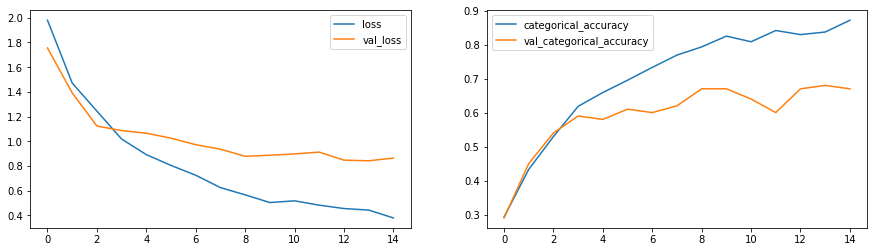

In [113]:
plot(history)

### Model is clearly overfitting. So we need to do data augmentation

# Model with Data Augmentation

In [114]:
batch_size = 40

In [115]:
# Generator
# This is one of the most important part of the code. The overall structure of the generator has been given. In the generator, you are going to preprocess the images as you have images of 2 different dimensions as well as create a batch of video frames. You have to experiment with img_idx, y,z and normalization such that you get high accuracy.

In [125]:
def generator(source_path, folder_list, batch_size, augment=True):
    print( 'Source path = ', source_path, '; batch size =', batch_size)
    img_idx = [0,1,2,4,6,8,10,12,14,16,18,20,22,24,26,27,28,29]
    while True:
        t = np.random.permutation(folder_list)
        num_batches = int(len(t)/batch_size)
        for batch in range(num_batches):
            batch_data = np.zeros((batch_size,18,84,84,3))
            batch_labels = np.zeros((batch_size,5))
            for folder in range(batch_size):
                imgs = os.listdir(source_path+'/'+ t[folder + (batch*batch_size)].split(';')[0])
                for idx,item in enumerate(img_idx):
                    image = imread(source_path+'/'+ t[folder + (batch*batch_size)].strip().split(';')[0]+'/'+imgs[item]).astype(np.float32)
                    if image.shape[1] == 160:
                        image = imresize(image[:,20:140,:],(84,84)).astype(np.float32)
                    else:
                        image = imresize(image,(84,84)).astype(np.float32)
                    
                    batch_data[folder,idx,:,:,0] = image[:,:,0] - 104
                    batch_data[folder,idx,:,:,1] = image[:,:,1] - 117
                    batch_data[folder,idx,:,:,2] = image[:,:,2] - 123
                    
                batch_labels[folder, int(t[folder + (batch*batch_size)].strip().split(';')[2])] = 1
            yield batch_data, batch_labels

        if (len(t)%batch_size) != 0:
            batch_data = np.zeros((len(t)%batch_size,18,84,84,3))
            batch_labels = np.zeros((len(t)%batch_size,5))
            for folder in range(len(t)%batch_size):
                imgs = os.listdir(source_path+'/'+ t[folder + (num_batches*batch_size)].split(';')[0])
                for idx,item in enumerate(img_idx):
                    image = imread(source_path+'/'+ t[folder + (num_batches*batch_size)].strip().split(';')[0]+'/'+imgs[item]).astype(np.float32)
                    if image.shape[1] == 160:
                        image = imresize(image[:,20:140,:],(84,84)).astype(np.float32)
                    else:
                        image = imresize(image,(84,84)).astype(np.float32)

                    batch_data[folder,idx,:,:,0] = image[:,:,0] - 104
                    batch_data[folder,idx,:,:,1] = image[:,:,1] - 117
                    batch_data[folder,idx,:,:,2] = image[:,:,2] - 123

                batch_labels[folder, int(t[folder + (num_batches*batch_size)].strip().split(';')[2])] = 1

            yield batch_data, batch_labels

In [126]:
# Note here that a video is represented above in the generator as (number of images, height, width, number of channels). Take this into consideration while creating the model architecture.

In [127]:
curr_dt_time = datetime.datetime.now()
train_path = 'train'
val_path = 'val'
num_train_sequences = len(train_doc)
print('# training sequences =', num_train_sequences)
num_val_sequences = len(val_doc)
print('# validation sequences =', num_val_sequences)
num_epochs = 30 # choose the number of epochs
print ('# epochs =', num_epochs)

# training sequences = 663
# validation sequences = 100
# epochs = 30


In [128]:
# Model
# Here you make the model using different functionalities that Keras provides. Remember to use Conv3D and MaxPooling3D and not Conv2D and Maxpooling2D for a 3D convolution model. You would want to use TimeDistributed while building a Conv2D + RNN model. Also remember that the last layer is the softmax. Design the network in such a way that the model is able to give good accuracy on the least number of parameters so that it can fit in the memory of the webcam.

In [129]:
#write your model here
input_shape = (18, 84, 84, 3)
model = Sequential([
    Conv3D(64, (3,3,3), strides=(1,1,1), padding='same', activation='relu', input_shape=input_shape),
    BatchNormalization(),
    MaxPooling3D(pool_size=(2,2,1), strides=(2,2,1)),
    
    Conv3D(128, (3,3,3), strides=(1,1,1), padding='same', activation='relu'),
    BatchNormalization(),
    MaxPooling3D(pool_size=(2,2,2), strides=(2,2,2)),    
    
    Conv3D(256, (3,3,3), strides=(1,1,1), padding='same', activation='relu'),
    BatchNormalization(),
    MaxPooling3D(pool_size=(2,2,2), strides=(2,2,2)),
    
    Conv3D(256, (3,3,3), strides=(1,1,1), padding='same', activation='relu'),
    BatchNormalization(),
    MaxPooling3D(pool_size=(2,2,2), strides=(2,2,2)),
    
       
    Flatten(),
    Dropout(0.5),
    Dense(512, activation='relu'),
    Dropout(0.5),
         
    Dense(5, activation='softmax')
])

In [130]:
# Now that you have written the model, the next step is to compile the model. When you print the summary of the model, you'll see the total number of parameters you have to train.

In [131]:
sgd = optimizers.SGD(lr=0.001, decay=1e-6, momentum=0.7, nesterov=True)
model.compile(optimizer=sgd, loss='categorical_crossentropy', metrics=['categorical_accuracy'])
print (model.summary())

_________________________________________________________________
Layer (type)                 Output Shape              Param #   
conv3d_33 (Conv3D)           (None, 18, 84, 84, 64)    5248      
_________________________________________________________________
batch_normalization_43 (Batc (None, 18, 84, 84, 64)    256       
_________________________________________________________________
max_pooling3d_33 (MaxPooling (None, 9, 42, 84, 64)     0         
_________________________________________________________________
conv3d_34 (Conv3D)           (None, 9, 42, 84, 128)    221312    
_________________________________________________________________
batch_normalization_44 (Batc (None, 9, 42, 84, 128)    512       
_________________________________________________________________
max_pooling3d_34 (MaxPooling (None, 4, 21, 42, 128)    0         
_________________________________________________________________
conv3d_35 (Conv3D)           (None, 4, 21, 42, 256)    884992    
__________

In [132]:
# Let us create the train_generator and the val_generator which will be used in .fit_generator.

In [133]:
train_generator = generator(train_path, train_doc, batch_size, augment=True)
val_generator = generator(val_path, val_doc, batch_size)

In [134]:
model_name = 'model_init' + '_' + str(curr_dt_time).replace(' ','').replace(':','_') + '/'
    
if not os.path.exists(model_name):
    os.mkdir(model_name)
        
filepath = model_name + 'model-{epoch:05d}-{loss:.5f}-{categorical_accuracy:.5f}-{val_loss:.5f}-{val_categorical_accuracy:.5f}.h5'

checkpoint = ModelCheckpoint(filepath, monitor='val_loss', verbose=1, save_best_only=False, save_weights_only=False, mode='auto', period=1)

LR = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, verbose=1, mode='min', epsilon=0.0001, cooldown=0, min_lr=0.00001)
callbacks_list = [checkpoint, LR]

In [135]:
# The steps_per_epoch and validation_steps are used by fit_generator to decide the number of next() calls it need to make.

In [136]:
if (num_train_sequences%batch_size) == 0:
    steps_per_epoch = int(num_train_sequences/batch_size)
else:
    steps_per_epoch = (num_train_sequences//batch_size) + 1

if (num_val_sequences%batch_size) == 0:
    validation_steps = int(num_val_sequences/batch_size)
else:
    validation_steps = (num_val_sequences//batch_size) + 1

In [137]:
# Let us now fit the model. This will start training the model and with the help of the checkpoints, you'll be able to save the model at the end of each epoch.

In [138]:
history_1=model.fit_generator(train_generator, steps_per_epoch=steps_per_epoch, epochs=num_epochs, verbose=1, 
                    callbacks=callbacks_list, validation_data=val_generator, 
                    validation_steps=validation_steps, class_weight=None, workers=1, initial_epoch=0)

Source path =  val ; batch size = 40
Source path =  train ; batch size = 40
Epoch 1/30
17/17 [==============================] - 58s 3s/step - loss: 3.5909 - categorical_accuracy: 0.3048 - val_loss: 3.6174 - val_categorical_accuracy: 0.2700

Epoch 00001: saving model to model_init_2021-01-3008_21_16.474664/model-00001-3.61709-0.30166-3.61735-0.27000.h5
Epoch 2/30
17/17 [==============================] - 48s 3s/step - loss: 1.9314 - categorical_accuracy: 0.4441 - val_loss: 0.9789 - val_categorical_accuracy: 0.6300

Epoch 00002: saving model to model_init_2021-01-3008_21_16.474664/model-00002-1.92962-0.44646-0.97888-0.63000.h5
Epoch 3/30
17/17 [==============================] - 48s 3s/step - loss: 1.4979 - categorical_accuracy: 0.5244 - val_loss: 1.0776 - val_categorical_accuracy: 0.6300

Epoch 00003: saving model to model_init_2021-01-3008_21_16.474664/model-00003-1.49916-0.52338-1.07761-0.63000.h5
Epoch 4/30
17/17 [==============================] - 48s 3s/step - loss: 1.1258 - categoric

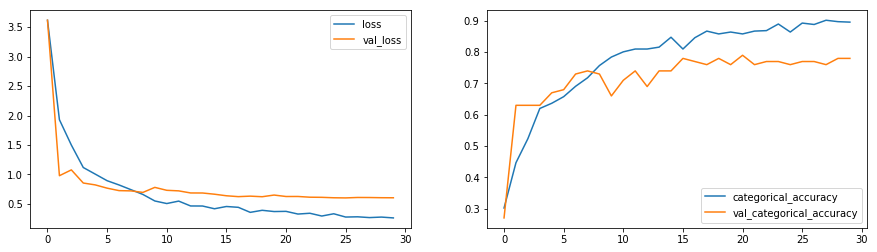

In [139]:
plot(history_1)

### Model is not overfitting and we get a best validation accuracy of 78% and training accuracy of 89%. Next we will try to reduce the filter size and image resolution and see if get better results.

# Experiments


# Model 1 - Adding more layers

In [7]:
train_doc = np.random.permutation(open('train.csv').readlines())
val_doc = np.random.permutation(open('val.csv').readlines())
batch_size = 20

In [8]:
def generator(source_path, folder_list, batch_size, augment=True):
    print( 'Source path = ', source_path, '; batch size =', batch_size)
    img_idx = [0,1,2,4,6,8,10,12,14,16,18,20,22,24,26,27,28,29]
    while True:
        t = np.random.permutation(folder_list)
        num_batches = int(len(t)/batch_size)
        for batch in range(num_batches):
            batch_data = np.zeros((batch_size,18,84,84,3))
            batch_labels = np.zeros((batch_size,5))
            for folder in range(batch_size):
                imgs = os.listdir(source_path+'/'+ t[folder + (batch*batch_size)].split(';')[0])
                for idx,item in enumerate(img_idx):
                    image = imread(source_path+'/'+ t[folder + (batch*batch_size)].strip().split(';')[0]+'/'+imgs[item]).astype(np.float32)
                    if image.shape[1] == 160:
                        image = imresize(image[:,20:140,:],(84,84)).astype(np.float32)
                    else:
                        image = imresize(image,(84,84)).astype(np.float32)
                    
                    batch_data[folder,idx,:,:,0] = image[:,:,0] - 104
                    batch_data[folder,idx,:,:,1] = image[:,:,1] - 117
                    batch_data[folder,idx,:,:,2] = image[:,:,2] - 123
                    
                batch_labels[folder, int(t[folder + (batch*batch_size)].strip().split(';')[2])] = 1
            yield batch_data, batch_labels

        if (len(t)%batch_size) != 0:
            batch_data = np.zeros((len(t)%batch_size,18,84,84,3))
            batch_labels = np.zeros((len(t)%batch_size,5))
            for folder in range(len(t)%batch_size):
                imgs = os.listdir(source_path+'/'+ t[folder + (num_batches*batch_size)].split(';')[0])
                for idx,item in enumerate(img_idx):
                    image = imread(source_path+'/'+ t[folder + (num_batches*batch_size)].strip().split(';')[0]+'/'+imgs[item]).astype(np.float32)
                    if image.shape[1] == 160:
                        image = imresize(image[:,20:140,:],(84,84)).astype(np.float32)
                    else:
                        image = imresize(image,(84,84)).astype(np.float32)

                    batch_data[folder,idx,:,:,0] = image[:,:,0] - 104
                    batch_data[folder,idx,:,:,1] = image[:,:,1] - 117
                    batch_data[folder,idx,:,:,2] = image[:,:,2] - 123

                batch_labels[folder, int(t[folder + (num_batches*batch_size)].strip().split(';')[2])] = 1

            yield batch_data, batch_labels

In [9]:
curr_dt_time = datetime.datetime.now()
train_path = 'train'
val_path = 'val'
num_train_sequences = len(train_doc)
print('# training sequences =', num_train_sequences)
num_val_sequences = len(val_doc)
print('# validation sequences =', num_val_sequences)
num_epochs = 15 # choose the number of epochs
print ('# epochs =', num_epochs)

# training sequences = 663
# validation sequences = 100
# epochs = 15


In [10]:
input_shape = (18, 84, 84, 3)
model_1 = Sequential([
    Conv3D(64, (3,3,3), strides=(1,1,1), padding='same', activation='relu', input_shape=input_shape),
    BatchNormalization(),
    
    
    Conv3D(64, (3,3,3), strides=(1,1,1), padding='same', activation='relu', input_shape=input_shape),
    BatchNormalization(),
    MaxPooling3D(pool_size=(2,2,1), strides=(2,2,1)),
    
    Conv3D(128, (3,3,3), strides=(1,1,1), padding='same', activation='relu'),
    BatchNormalization(),
    
    
    Conv3D(128, (3,3,3), strides=(1,1,1), padding='same', activation='relu'),
    BatchNormalization(),
    MaxPooling3D(pool_size=(2,2,2), strides=(2,2,2)),
    
    Conv3D(256, (3,3,3), strides=(1,1,1), padding='same', activation='relu'),
    BatchNormalization(),
    
    
    Conv3D(256, (3,3,3), strides=(1,1,1), padding='same', activation='relu'),
    BatchNormalization(),
    MaxPooling3D(pool_size=(2,2,2), strides=(2,2,2)),   
      
       
    Flatten(),
    Dropout(0.5),
    Dense(512, activation='relu'),
    Dropout(0.5),
         
    Dense(5, activation='softmax')
])

In [11]:
sgd = optimizers.SGD(lr=0.001, decay=1e-6, momentum=0.7, nesterov=True)
model_1.compile(optimizer=sgd, loss='categorical_crossentropy', metrics=['categorical_accuracy'])
print (model_1.summary())

_________________________________________________________________
Layer (type)                 Output Shape              Param #   
conv3d_1 (Conv3D)            (None, 18, 84, 84, 64)    5248      
_________________________________________________________________
batch_normalization_1 (Batch (None, 18, 84, 84, 64)    256       
_________________________________________________________________
conv3d_2 (Conv3D)            (None, 18, 84, 84, 64)    110656    
_________________________________________________________________
batch_normalization_2 (Batch (None, 18, 84, 84, 64)    256       
_________________________________________________________________
max_pooling3d_1 (MaxPooling3 (None, 9, 42, 84, 64)     0         
_________________________________________________________________
conv3d_3 (Conv3D)            (None, 9, 42, 84, 128)    221312    
_________________________________________________________________
batch_normalization_3 (Batch (None, 9, 42, 84, 128)    512       
__________

In [12]:
train_generator = generator(train_path, train_doc, batch_size,augment=True)
val_generator = generator(val_path, val_doc, batch_size)

In [13]:
model_name = 'model_init' + '_' + str(curr_dt_time).replace(' ','').replace(':','_') + '/'
    
if not os.path.exists(model_name):
    os.mkdir(model_name)
        
filepath = model_name + 'model-{epoch:05d}-{loss:.5f}-{categorical_accuracy:.5f}-{val_loss:.5f}-{val_categorical_accuracy:.5f}.h5'

checkpoint = ModelCheckpoint(filepath, monitor='val_loss', verbose=1, save_best_only=False, save_weights_only=False, mode='auto', period=1)

LR = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, verbose=1, mode='min', epsilon=0.0001, cooldown=0, min_lr=0.00001)
callbacks_list = [checkpoint, LR]

In [14]:
if (num_train_sequences%batch_size) == 0:
    steps_per_epoch = int(num_train_sequences/batch_size)
else:
    steps_per_epoch = (num_train_sequences//batch_size) + 1

if (num_val_sequences%batch_size) == 0:
    validation_steps = int(num_val_sequences/batch_size)
else:
    validation_steps = (num_val_sequences//batch_size) + 1

In [15]:
history_2= model_1.fit_generator(train_generator, steps_per_epoch=steps_per_epoch, epochs=num_epochs, verbose=1, 
                    callbacks=callbacks_list, validation_data=val_generator, 
                    validation_steps=validation_steps, class_weight=None, workers=1, initial_epoch=0)

Source path =  val ; batch size = 20
Source path =  train ; batch size = 20
Epoch 1/15
34/34 [==============================] - 209s 6s/step - loss: 12.2455 - categorical_accuracy: 0.2016 - val_loss: 12.5287 - val_categorical_accuracy: 0.2100

Epoch 00001: saving model to model_init_2021-01-3017_47_50.963679/model-00001-12.14906-0.20664-12.52874-0.21000.h5
Epoch 2/15
34/34 [==============================] - 159s 5s/step - loss: 10.5570 - categorical_accuracy: 0.3194 - val_loss: 11.7080 - val_categorical_accuracy: 0.2400

Epoch 00002: saving model to model_init_2021-01-3017_47_50.963679/model-00002-10.43106-0.32730-11.70798-0.24000.h5
Epoch 3/15
34/34 [==============================] - 160s 5s/step - loss: 7.7102 - categorical_accuracy: 0.4069 - val_loss: 7.3896 - val_categorical_accuracy: 0.4700

Epoch 00003: saving model to model_init_2021-01-3017_47_50.963679/model-00003-7.63429-0.40875-7.38956-0.47000.h5
Epoch 4/15
34/34 [==============================] - 160s 5s/step - loss: 4.9629

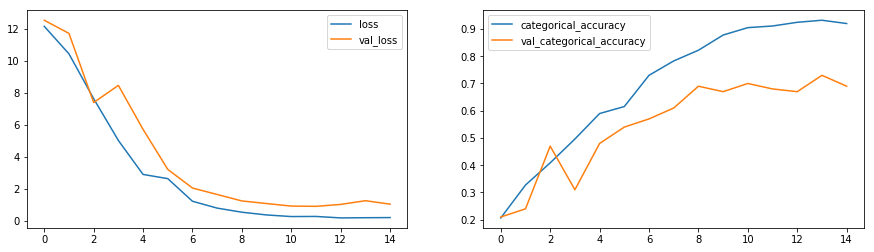

In [16]:
plot(history_2)

### After adding more layesrs to Model as resultant, number of parameters increased and training time is also increased.Model is also overfittig.  

# Model 2 - Reduce filter size to (2,2,2)

In [17]:
batch_size = 20

In [18]:
def generator(source_path, folder_list, batch_size):
    print( 'Source path = ', source_path, '; batch size =', batch_size)
    img_idx = [0,1,2,4,6,8,10,12,14,16,18,20,22,24,26,27,28,29]
    while True:
        t = np.random.permutation(folder_list)
        num_batches = int(len(t)/batch_size)
        for batch in range(num_batches):
            batch_data = np.zeros((batch_size,18,84,84,3))
            batch_labels = np.zeros((batch_size,5))
            for folder in range(batch_size):
                imgs = os.listdir(source_path+'/'+ t[folder + (batch*batch_size)].split(';')[0])
                for idx,item in enumerate(img_idx):
                    image = imread(source_path+'/'+ t[folder + (batch*batch_size)].strip().split(';')[0]+'/'+imgs[item]).astype(np.float32)
                    if image.shape[1] == 160:
                        image = imresize(image[:,20:140,:],(84,84)).astype(np.float32)
                    else:
                        image = imresize(image,(84,84)).astype(np.float32)
                    
                    batch_data[folder,idx,:,:,0] = image[:,:,0] - 104
                    batch_data[folder,idx,:,:,1] = image[:,:,1] - 117
                    batch_data[folder,idx,:,:,2] = image[:,:,2] - 123
                    
                batch_labels[folder, int(t[folder + (batch*batch_size)].strip().split(';')[2])] = 1
            yield batch_data, batch_labels

        if (len(t)%batch_size) != 0:
            batch_data = np.zeros((len(t)%batch_size,18,84,84,3))
            batch_labels = np.zeros((len(t)%batch_size,5))
            for folder in range(len(t)%batch_size):
                imgs = os.listdir(source_path+'/'+ t[folder + (num_batches*batch_size)].split(';')[0])
                for idx,item in enumerate(img_idx):
                    image = imread(source_path+'/'+ t[folder + (num_batches*batch_size)].strip().split(';')[0]+'/'+imgs[item]).astype(np.float32)
                    if image.shape[1] == 160:
                        image = imresize(image[:,20:140,:],(84,84)).astype(np.float32)
                    else:
                        image = imresize(image,(84,84)).astype(np.float32)

                    batch_data[folder,idx,:,:,0] = image[:,:,0] - 104
                    batch_data[folder,idx,:,:,1] = image[:,:,1] - 117
                    batch_data[folder,idx,:,:,2] = image[:,:,2] - 123

                batch_labels[folder, int(t[folder + (num_batches*batch_size)].strip().split(';')[2])] = 1

            yield batch_data, batch_labels

In [19]:
curr_dt_time = datetime.datetime.now()
train_path = 'train'
val_path = 'val'
num_train_sequences = len(train_doc)
print('# training sequences =', num_train_sequences)
num_val_sequences = len(val_doc)
print('# validation sequences =', num_val_sequences)
num_epochs = 15 # choose the number of epochs
print ('# epochs =', num_epochs)

# training sequences = 663
# validation sequences = 100
# epochs = 15


In [20]:
input_shape = (18, 84, 84, 3)
model_2 = Sequential([
    Conv3D(64, (2,2,2), strides=(1,1,1), padding='same', activation='relu', input_shape=input_shape),
    BatchNormalization(),
    MaxPooling3D(pool_size=(2,2,1), strides=(2,2,1)),
    
    Conv3D(128, (2,2,2), strides=(1,1,1), padding='same', activation='relu'),
    BatchNormalization(),
    MaxPooling3D(pool_size=(2,2,2), strides=(2,2,2)),
           
    Conv3D(256, (2,2,2), strides=(1,1,1), padding='same', activation='relu'),
    BatchNormalization(),
    MaxPooling3D(pool_size=(2,2,2), strides=(2,2,2)),
    
    
    Conv3D(256, (2,3,2), strides=(1,1,1), padding='same', activation='relu'),
    BatchNormalization(),
    MaxPooling3D(pool_size=(2,2,2), strides=(2,2,2)),   
      
       
    Flatten(),
    Dropout(0.5),
    Dense(512, activation='relu'),
    Dropout(0.5),
         
    Dense(5, activation='softmax')
])

In [21]:
sgd = optimizers.SGD(lr=0.001, decay=1e-6, momentum=0.7, nesterov=True)
model_2.compile(optimizer=sgd, loss='categorical_crossentropy', metrics=['categorical_accuracy'])
print (model_2.summary())

_________________________________________________________________
Layer (type)                 Output Shape              Param #   
conv3d_7 (Conv3D)            (None, 18, 84, 84, 64)    1600      
_________________________________________________________________
batch_normalization_7 (Batch (None, 18, 84, 84, 64)    256       
_________________________________________________________________
max_pooling3d_4 (MaxPooling3 (None, 9, 42, 84, 64)     0         
_________________________________________________________________
conv3d_8 (Conv3D)            (None, 9, 42, 84, 128)    65664     
_________________________________________________________________
batch_normalization_8 (Batch (None, 9, 42, 84, 128)    512       
_________________________________________________________________
max_pooling3d_5 (MaxPooling3 (None, 4, 21, 42, 128)    0         
_________________________________________________________________
conv3d_9 (Conv3D)            (None, 4, 21, 42, 256)    262400    
__________

In [22]:
train_generator = generator(train_path, train_doc, batch_size)
val_generator = generator(val_path, val_doc, batch_size)

In [23]:
model_name = 'model_init' + '_' + str(curr_dt_time).replace(' ','').replace(':','_') + '/'
    
if not os.path.exists(model_name):
    os.mkdir(model_name)
        
filepath = model_name + 'model-{epoch:05d}-{loss:.5f}-{categorical_accuracy:.5f}-{val_loss:.5f}-{val_categorical_accuracy:.5f}.h5'

checkpoint = ModelCheckpoint(filepath, monitor='val_loss', verbose=1, save_best_only=False, save_weights_only=False, mode='auto', period=1)

LR = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, verbose=1, mode='min', epsilon=0.0001, cooldown=0, min_lr=0.00001)
callbacks_list = [checkpoint, LR]

In [24]:
if (num_train_sequences%batch_size) == 0:
    steps_per_epoch = int(num_train_sequences/batch_size)
else:
    steps_per_epoch = (num_train_sequences//batch_size) + 1

if (num_val_sequences%batch_size) == 0:
    validation_steps = int(num_val_sequences/batch_size)
else:
    validation_steps = (num_val_sequences//batch_size) + 1

In [25]:
history_3 = model_2.fit_generator(train_generator, steps_per_epoch=steps_per_epoch, epochs=num_epochs, verbose=1, 
                    callbacks=callbacks_list, validation_data=val_generator, 
                    validation_steps=validation_steps, class_weight=None, workers=1, initial_epoch=0)

Source path = Source path =  train ; batch size = 20
 val ; batch size = 20
Epoch 1/15
34/34 [==============================] - 51s 1s/step - loss: 3.5600 - categorical_accuracy: 0.3812 - val_loss: 3.0552 - val_categorical_accuracy: 0.3200

Epoch 00001: saving model to model_init_2021-01-3018_34_02.480549/model-00001-3.62552-0.37406-3.05523-0.32000.h5
Epoch 2/15
34/34 [==============================] - 44s 1s/step - loss: 1.8900 - categorical_accuracy: 0.4996 - val_loss: 2.3962 - val_categorical_accuracy: 0.4000

Epoch 00002: saving model to model_init_2021-01-3018_34_02.480549/model-00002-1.86216-0.50377-2.39623-0.40000.h5
Epoch 3/15
34/34 [==============================] - 44s 1s/step - loss: 1.3226 - categorical_accuracy: 0.5806 - val_loss: 0.9191 - val_categorical_accuracy: 0.6800

Epoch 00003: saving model to model_init_2021-01-3018_34_02.480549/model-00003-1.35066-0.57014-0.91910-0.68000.h5
Epoch 4/15
34/34 [==============================] - 45s 1s/step - loss: 0.9554 - categoric

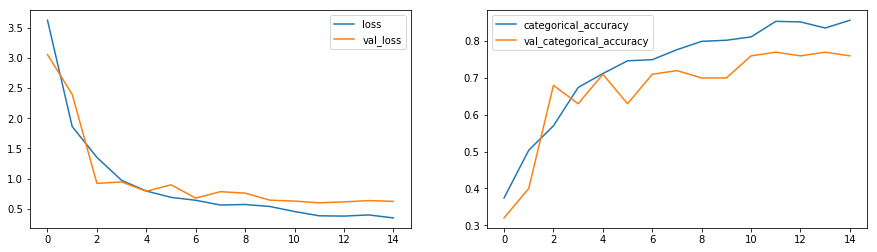

In [26]:
plot(history_3)

### After reducing the filter size, we get a best validation accuracy of 76% and training accuracy of 86%.

# Model 3 - Reduce image resolution to 120X120

In [27]:
batch_size = 20

In [28]:
def generator(source_path, folder_list, batch_size):
    print( 'Source path = ', source_path, '; batch size =', batch_size)
    img_idx = [0,1,2,4,6,8,10,12,14,16,18,20,22,24,26,27,28,29]
    while True:
        t = np.random.permutation(folder_list)
        num_batches = int(len(t)/batch_size)
        for batch in range(num_batches):
            batch_data = np.zeros((batch_size,18,120,120,3))
            batch_labels = np.zeros((batch_size,5))
            for folder in range(batch_size):
                imgs = os.listdir(source_path+'/'+ t[folder + (batch*batch_size)].split(';')[0])
                for idx,item in enumerate(img_idx):
                    image = imread(source_path+'/'+ t[folder + (batch*batch_size)].strip().split(';')[0]+'/'+imgs[item]).astype(np.float32)
                    if image.shape[1] == 160:
                        image = imresize(image[:,20:140,:],(120,120)).astype(np.float32)
                    else:
                        image = imresize(image,(120,120)).astype(np.float32)
                    
                    batch_data[folder,idx,:,:,0] = image[:,:,0] - 104
                    batch_data[folder,idx,:,:,1] = image[:,:,1] - 117
                    batch_data[folder,idx,:,:,2] = image[:,:,2] - 123
                    
                batch_labels[folder, int(t[folder + (batch*batch_size)].strip().split(';')[2])] = 1
            yield batch_data, batch_labels

        if (len(t)%batch_size) != 0:
            batch_data = np.zeros((len(t)%batch_size,18,120,120,3))
            batch_labels = np.zeros((len(t)%batch_size,5))
            for folder in range(len(t)%batch_size):
                imgs = os.listdir(source_path+'/'+ t[folder + (num_batches*batch_size)].split(';')[0])
                for idx,item in enumerate(img_idx):
                    image = imread(source_path+'/'+ t[folder + (num_batches*batch_size)].strip().split(';')[0]+'/'+imgs[item]).astype(np.float32)
                    if image.shape[1] == 160:
                        image = imresize(image[:,20:140,:],(120,120)).astype(np.float32)
                    else:
                        image = imresize(image,(120,120)).astype(np.float32)

                    batch_data[folder,idx,:,:,0] = image[:,:,0] - 104
                    batch_data[folder,idx,:,:,1] = image[:,:,1] - 117
                    batch_data[folder,idx,:,:,2] = image[:,:,2] - 123

                batch_labels[folder, int(t[folder + (num_batches*batch_size)].strip().split(';')[2])] = 1

            yield batch_data, batch_labels

In [29]:
curr_dt_time = datetime.datetime.now()
train_path = 'train'
val_path = 'val'
num_train_sequences = len(train_doc)
print('# training sequences =', num_train_sequences)
num_val_sequences = len(val_doc)
print('# validation sequences =', num_val_sequences)
num_epochs = 15 # choose the number of epochs
print ('# epochs =', num_epochs)

# training sequences = 663
# validation sequences = 100
# epochs = 15


In [30]:
input_shape = (18, 120, 120, 3)
model_3 = Sequential([
    Conv3D(64, (2,2,2), strides=(1,1,1), padding='same', activation='relu', input_shape=input_shape),
    BatchNormalization(),
    MaxPooling3D(pool_size=(2,2,2), strides=(2,2,2)),
    
    Conv3D(128, (2,2,2), strides=(1,1,1), padding='same', activation='relu'),
    BatchNormalization(),
    MaxPooling3D(pool_size=(2,2,2), strides=(2,2,2)),
           
    Conv3D(256, (2,2,2), strides=(1,1,1), padding='same', activation='relu'),
    BatchNormalization(),
    MaxPooling3D(pool_size=(2,2,2), strides=(2,2,2)),
    
    
    Conv3D(256, (2,3,2), strides=(1,1,1), padding='same', activation='relu'),
    BatchNormalization(),
    MaxPooling3D(pool_size=(2,2,2), strides=(2,2,2)),   
      
       
    Flatten(),
    Dropout(0.5),
    Dense(512, activation='relu'),
    Dropout(0.5),
         
    Dense(5, activation='softmax')
])

In [31]:
sgd = optimizers.SGD(lr=0.001, decay=1e-6, momentum=0.7, nesterov=True)
model_3.compile(optimizer=sgd, loss='categorical_crossentropy', metrics=['categorical_accuracy'])
print (model_3.summary())

_________________________________________________________________
Layer (type)                 Output Shape              Param #   
conv3d_11 (Conv3D)           (None, 18, 120, 120, 64)  1600      
_________________________________________________________________
batch_normalization_11 (Batc (None, 18, 120, 120, 64)  256       
_________________________________________________________________
max_pooling3d_8 (MaxPooling3 (None, 9, 60, 60, 64)     0         
_________________________________________________________________
conv3d_12 (Conv3D)           (None, 9, 60, 60, 128)    65664     
_________________________________________________________________
batch_normalization_12 (Batc (None, 9, 60, 60, 128)    512       
_________________________________________________________________
max_pooling3d_9 (MaxPooling3 (None, 4, 30, 30, 128)    0         
_________________________________________________________________
conv3d_13 (Conv3D)           (None, 4, 30, 30, 256)    262400    
__________

In [32]:
train_generator = generator(train_path, train_doc, batch_size)
val_generator = generator(val_path, val_doc, batch_size)

In [33]:
model_name = 'model_init' + '_' + str(curr_dt_time).replace(' ','').replace(':','_') + '/'
    
if not os.path.exists(model_name):
    os.mkdir(model_name)
        
filepath = model_name + 'model-{epoch:05d}-{loss:.5f}-{categorical_accuracy:.5f}-{val_loss:.5f}-{val_categorical_accuracy:.5f}.h5'

checkpoint = ModelCheckpoint(filepath, monitor='val_loss', verbose=1, save_best_only=False, save_weights_only=False, mode='auto', period=1)

LR = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, verbose=1, mode='min', epsilon=0.0001, cooldown=0, min_lr=0.00001)
callbacks_list = [checkpoint, LR]

In [34]:
if (num_train_sequences%batch_size) == 0:
    steps_per_epoch = int(num_train_sequences/batch_size)
else:
    steps_per_epoch = (num_train_sequences//batch_size) + 1

if (num_val_sequences%batch_size) == 0:
    validation_steps = int(num_val_sequences/batch_size)
else:
    validation_steps = (num_val_sequences//batch_size) + 1

In [35]:
history_4 = model_3.fit_generator(train_generator, steps_per_epoch=steps_per_epoch, epochs=num_epochs, verbose=1, 
                    callbacks=callbacks_list, validation_data=val_generator, 
                    validation_steps=validation_steps, class_weight=None, workers=1, initial_epoch=0)

Source path =  val ; batch size = 20
Source path =  train ; batch size = 20
Epoch 1/15
34/34 [==============================] - 57s 2s/step - loss: 3.3588 - categorical_accuracy: 0.3620 - val_loss: 2.6935 - val_categorical_accuracy: 0.3300

Epoch 00001: saving model to model_init_2021-01-3018_46_44.960807/model-00001-3.42464-0.35445-2.69350-0.33000.h5
Epoch 2/15
34/34 [==============================] - 46s 1s/step - loss: 1.5675 - categorical_accuracy: 0.5467 - val_loss: 1.4487 - val_categorical_accuracy: 0.5800

Epoch 00002: saving model to model_init_2021-01-3018_46_44.960807/model-00002-1.60288-0.53544-1.44871-0.58000.h5
Epoch 3/15
34/34 [==============================] - 46s 1s/step - loss: 1.1693 - categorical_accuracy: 0.5894 - val_loss: 1.1146 - val_categorical_accuracy: 0.6100

Epoch 00003: saving model to model_init_2021-01-3018_46_44.960807/model-00003-1.16507-0.59578-1.11456-0.61000.h5
Epoch 4/15
34/34 [==============================] - 46s 1s/step - loss: 0.9825 - categoric

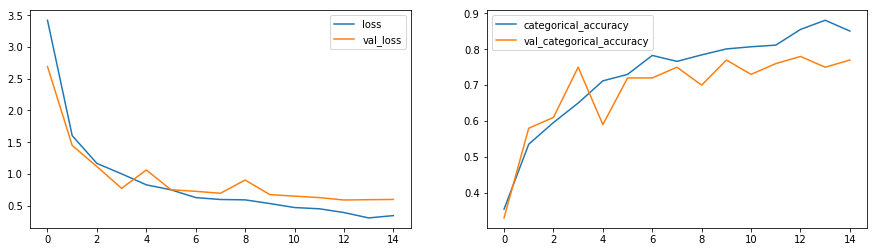

In [36]:
plot(history_4)

### After reducing the image resolution size, there is not much difference in validation accuracy and training accuracy.

# Model 4 - CNN-RNN (LSTM)

In [37]:
train_doc = np.random.permutation(open('train.csv').readlines())
val_doc = np.random.permutation(open('val.csv').readlines())
batch_size = 20

In [38]:
def generator(source_path, folder_list, batch_size):
    print( 'Source path = ', source_path, '; batch size =', batch_size)
    img_idx = [0,1,2,4,6,8,10,12,14,16,18,20,22,24,26,27,28,29]
    while True:
        t = np.random.permutation(folder_list)
        num_batches = int(len(t)/batch_size)
        for batch in range(num_batches):
            batch_data = np.zeros((batch_size,18,120,120,3))
            batch_labels = np.zeros((batch_size,5))
            for folder in range(batch_size):
                imgs = os.listdir(source_path+'/'+ t[folder + (batch*batch_size)].split(';')[0])
                for idx,item in enumerate(img_idx):
                    image = imread(source_path+'/'+ t[folder + (batch*batch_size)].strip().split(';')[0]+'/'+imgs[item]).astype(np.float32)
                    if image.shape[1] == 160:
                        image = imresize(image[:,20:140,:],(120,120)).astype(np.float32)
                    else:
                        image = imresize(image,(120,120)).astype(np.float32)
                    
                    batch_data[folder,idx,:,:,0] = image[:,:,0] - 104
                    batch_data[folder,idx,:,:,1] = image[:,:,1] - 117
                    batch_data[folder,idx,:,:,2] = image[:,:,2] - 123
                    
                batch_labels[folder, int(t[folder + (batch*batch_size)].strip().split(';')[2])] = 1
            yield batch_data, batch_labels

        if (len(t)%batch_size) != 0:
            batch_data = np.zeros((len(t)%batch_size,18,120,120,3))
            batch_labels = np.zeros((len(t)%batch_size,5))
            for folder in range(len(t)%batch_size):
                imgs = os.listdir(source_path+'/'+ t[folder + (num_batches*batch_size)].split(';')[0])
                for idx,item in enumerate(img_idx):
                    image = imread(source_path+'/'+ t[folder + (num_batches*batch_size)].strip().split(';')[0]+'/'+imgs[item]).astype(np.float32)
                    if image.shape[1] == 160:
                        image = imresize(image[:,20:140,:],(120,120)).astype(np.float32)
                    else:
                        image = imresize(image,(120,120)).astype(np.float32)

                    batch_data[folder,idx,:,:,0] = image[:,:,0] - 104
                    batch_data[folder,idx,:,:,1] = image[:,:,1] - 117
                    batch_data[folder,idx,:,:,2] = image[:,:,2] - 123

                batch_labels[folder, int(t[folder + (num_batches*batch_size)].strip().split(';')[2])] = 1

            yield batch_data, batch_labels

In [39]:
curr_dt_time = datetime.datetime.now()
train_path = 'train'
val_path = 'val'
num_train_sequences = len(train_doc)
print('# training sequences =', num_train_sequences)
num_val_sequences = len(val_doc)
print('# validation sequences =', num_val_sequences)
num_epochs = 15 # choose the number of epochs
print ('# epochs =', num_epochs)

# training sequences = 663
# validation sequences = 100
# epochs = 15


In [40]:
#write your model here
from keras.models import Sequential, Model
from keras.layers import Conv2D,MaxPooling2D
from keras.callbacks import ModelCheckpoint, ReduceLROnPlateau
from keras.layers import Dense, GRU, Flatten, TimeDistributed, Flatten, BatchNormalization, Activation, Dropout, LSTM, Bidirectional


Input_shape_1 = (18, 120, 120, 3)
model = Sequential()
model.add(TimeDistributed(Conv2D(32, (3, 3), strides=(2, 2), activation='relu', padding='same'), input_shape=Input_shape_1))
model.add(TimeDistributed(Conv2D(32, (3,3), kernel_initializer="he_normal", activation='relu')))
model.add(TimeDistributed(MaxPooling2D((2, 2), strides=(2, 2))))
 
model.add(TimeDistributed(Conv2D(64, (3,3), padding='same', activation='relu')))
model.add(TimeDistributed(Conv2D(64, (3,3), padding='same', activation='relu')))
model.add(TimeDistributed(MaxPooling2D((2, 2), strides=(2, 2))))
 
model.add(TimeDistributed(Conv2D(128, (3,3), padding='same', activation='relu')))
model.add(TimeDistributed(Conv2D(128, (3,3), padding='same', activation='relu')))
model.add(TimeDistributed(MaxPooling2D((2, 2), strides=(2, 2))))
 
model.add(TimeDistributed(Conv2D(256, (3,3), padding='same', activation='relu')))
model.add(TimeDistributed(Conv2D(256, (3,3), padding='same', activation='relu')))
model.add(TimeDistributed(MaxPooling2D((2, 2), strides=(2, 2))))
 
model.add(TimeDistributed(Conv2D(512, (3,3), padding='same', activation='relu')))
model.add(TimeDistributed(Conv2D(512, (3,3), padding='same', activation='relu')))
model.add(TimeDistributed(MaxPooling2D((2, 2), strides=(2, 2))))
 
model.add(TimeDistributed(Flatten()))
 
model.add(Dropout(0.5))
model.add(LSTM(512, return_sequences=False, dropout=0.5))
model.add(Dense(5, activation='softmax'))
#model.summary()



In [41]:
sgd = optimizers.SGD(lr=0.001, decay=1e-6, momentum=0.7, nesterov=True)
model.compile(optimizer=sgd, loss='categorical_crossentropy', metrics=['categorical_accuracy'])
print (model.summary())

_________________________________________________________________
Layer (type)                 Output Shape              Param #   
time_distributed_1 (TimeDist (None, 18, 60, 60, 32)    896       
_________________________________________________________________
time_distributed_2 (TimeDist (None, 18, 58, 58, 32)    9248      
_________________________________________________________________
time_distributed_3 (TimeDist (None, 18, 29, 29, 32)    0         
_________________________________________________________________
time_distributed_4 (TimeDist (None, 18, 29, 29, 64)    18496     
_________________________________________________________________
time_distributed_5 (TimeDist (None, 18, 29, 29, 64)    36928     
_________________________________________________________________
time_distributed_6 (TimeDist (None, 18, 14, 14, 64)    0         
_________________________________________________________________
time_distributed_7 (TimeDist (None, 18, 14, 14, 128)   73856     
__________

In [42]:
train_generator = generator(train_path, train_doc, batch_size)
val_generator = generator(val_path, val_doc, batch_size)

In [43]:
model_name = 'model_init' + '_' + str(curr_dt_time).replace(' ','').replace(':','_') + '/'
    
if not os.path.exists(model_name):
    os.mkdir(model_name)
        
filepath = model_name + 'model-{epoch:05d}-{loss:.5f}-{categorical_accuracy:.5f}-{val_loss:.5f}-{val_categorical_accuracy:.5f}.h5'

checkpoint = ModelCheckpoint(filepath, monitor='val_loss', verbose=1, save_best_only=False, save_weights_only=False, mode='auto', period=1)

LR = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, verbose=1, mode='min', epsilon=0.0001, cooldown=0, min_lr=0.00001)
callbacks_list = [checkpoint, LR]

In [44]:
if (num_train_sequences%batch_size) == 0:
    steps_per_epoch = int(num_train_sequences/batch_size)
else:
    steps_per_epoch = (num_train_sequences//batch_size) + 1

if (num_val_sequences%batch_size) == 0:
    validation_steps = int(num_val_sequences/batch_size)
else:
    validation_steps = (num_val_sequences//batch_size) + 1

In [45]:
history_5 = model.fit_generator(train_generator, steps_per_epoch=steps_per_epoch, epochs=num_epochs, verbose=1, 
                    callbacks=callbacks_list, validation_data=val_generator, 
                    validation_steps=validation_steps, class_weight=None, workers=1, initial_epoch=0)

Source path =  val ; batch size = 20
Source path =  train ; batch size = 20
Epoch 1/15
34/34 [==============================] - 50s 1s/step - loss: 1.6673 - categorical_accuracy: 0.2053 - val_loss: 1.6118 - val_categorical_accuracy: 0.1800

Epoch 00001: saving model to model_init_2021-01-3018_59_31.191169/model-00001-1.66763-0.20211-1.61184-0.18000.h5
Epoch 2/15
34/34 [==============================] - 43s 1s/step - loss: 1.5905 - categorical_accuracy: 0.2362 - val_loss: 1.5078 - val_categorical_accuracy: 0.3000

Epoch 00002: saving model to model_init_2021-01-3018_59_31.191169/model-00002-1.59424-0.23379-1.50779-0.30000.h5
Epoch 3/15
34/34 [==============================] - 45s 1s/step - loss: 1.5456 - categorical_accuracy: 0.3098 - val_loss: 1.4092 - val_categorical_accuracy: 0.4200

Epoch 00003: saving model to model_init_2021-01-3018_59_31.191169/model-00003-1.54563-0.30920-1.40925-0.42000.h5
Epoch 4/15
34/34 [==============================] - 45s 1s/step - loss: 1.4566 - categoric

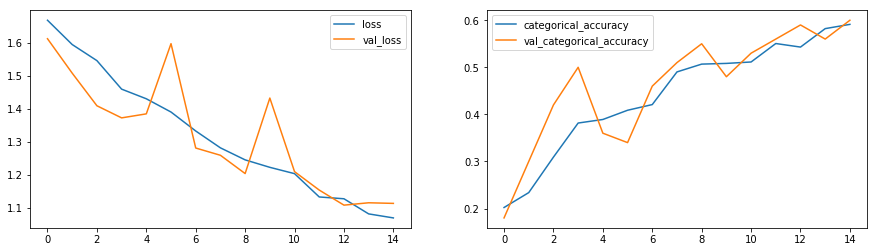

In [46]:
plot(history_5)